# R4 · Logique, ensembles, Σ et Π — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r4_logique_ensembles/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R4.1 à R4.8, R4.14 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | R4.17 | Tables de vérité et implication · `truth_table`, `implies` | 🔨 | ★ | 30 |
|  | R4.19 | Chercher un contre-exemple de 0 à N · `find_counterexample` | 🔨 | ★★ | 30 |
|  | R4.21 | Prédire : n² + n + 41 est-il toujours un nombre premier ? | 🔮 | ★ | 15 |
| B | R4.20 | Les ensembles de Python : `set`, `\|`, `&`, `-` | 📦 | ★ | 10 |
|  | R4.23 | Diagrammes de Venn | 🎨 | ★ | 15 |
| C | R4.18 | Σ et Π en Python · `sum_over`, `prod_over` | 🔨 | ★ | 25 |
|  | R4.22 | Vérifier une formule de somme de 1 à 1 000, puis la démontrer | 🔬 | ★★ | 20 |
|  | R4.24 | Chasse à l'erreur : une « démonstration » par récurrence qui prouve le faux | 🐛 | ★★ | 20 |
|  | R4.25 | Rédiger une démonstration propre en LaTeX | 🛠️ | ★ | 20 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : tables de vérité, implications, quantificateurs, ensembles, sommes Σ et produits Π, contre-exemples, une loss moyenne.
- Écrire les cinq fonctions de `mymath/logic.py` et les tester.
- Voir une propriété tenir 40 fois puis tomber, vérifier une formule mille fois puis la démontrer, chasser l'erreur dans deux récurrences.

**Rappel express.** $P \Rightarrow Q$ n'est fausse que si P est vraie et Q fausse ; elle équivaut à sa contraposée $\text{non } Q \Rightarrow \text{non } P$, pas à sa réciproque. Nier : « pour tout » devient « il existe », « et » devient « ou ». $\lvert A \cup B \rvert = \lvert A \rvert + \lvert B \rvert - \lvert A \cap B \rvert$. $\sum_{k=m}^{n}$ a $n - m + 1$ termes, bornes incluses : `range(m, n + 1)`. Récurrence : initialisation, hérédité, conclusion.

## Partie 0 · Vérifier tes exercices papier (✏️ R4.1 à R4.8, 🔗 R4.14)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- une colonne de table de vérité par la liste de ses valeurs, dans l'ordre des lignes VV, VF, FV, FF : `[True, False, False, False]` pour « P et Q » (ou les lettres V et F, entre guillemets) ;
- vrai ou faux par `True` ou `False` ; un numéro de réponse proposée par un entier ;
- un ensemble par la liste de ses éléments, dans l'ordre que tu veux, la liste vide pour $\varnothing$ ;
- un nombre avec un point décimal, `-1.5` ; une fraction exacte entre guillemets, `"5/7"` ;
- une expression entre guillemets, `"3*n**2 + 1"` ; un intervalle entre guillemets, `"]-1 ; 4]"`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import itertools
import math
from fractions import Fraction

T, F = True, False
ROWS2 = list(itertools.product([True, False], repeat=2))          # VV, VF, FV, FF
ROWS3 = list(itertools.product([True, False], repeat=3))
E = set(range(1, 26))                                             # R4.4
SQUARES = {k * k for k in range(1, 6)}
PRIMES = {n for n in E if n > 1 and all(n % d for d in range(2, n))}
LATE = {n for n in E if n >= 17}
B_SET = {1, 2, 3}                                                 # R4.5
PAIRS_AB = {(a, b) for a in (0, 1) for b in B_SET}
TRUE_Y, PRED_Y = [3, 5, 2, 8, 6], [4, 5, 1, 6, 6]                 # R4.14
ERRORS = [p - y for p, y in zip(PRED_Y, TRUE_Y)]
OUTLIER = ERRORS[:4] + [16 - 6]

**Ex R4.1 — Tables de vérité de « et », « ou », « non » et de l'implication**

In [3]:
wbm.record("R4.1a", [not (p and q) for p, q in ROWS2], mistakes={"non (P et Q) est vraie dès qu'une des deux est fausse : ce n'est pas « ni P ni Q »": [F, F, F, T], "c'est la colonne de « P et Q » : il reste à la nier": [T, F, F, F]})
wbm.record("R4.1b", [(not p) or (not q) for p, q in ROWS2], mistakes={"« ou » est vraie dès qu'au moins une des deux est vraie": [F, F, F, T]})
wbm.record("R4.1c", True, mistakes={"compare les deux colonnes ligne par ligne : ce sont les lois de De Morgan": False})
wbm.record("R4.1d", [(not p) or q for p, q in ROWS2], mistakes={"quand P est fausse, P ⇒ Q est vraie : elle n'est fausse que si P est vraie et Q fausse": [T, F, F, F], "c'est la colonne de Q ⇒ P, la réciproque": [T, T, F, T], "c'est la colonne de la négation de P ⇒ Q": [F, T, F, F]})
wbm.record("R4.1e", [(not q) or p for p, q in ROWS2], mistakes={"Q ⇒ P n'est fausse que si Q est vraie et P fausse : regarde la ligne FV": [T, F, T, T], "Q ⇒ P est vraie quand Q est fausse": [T, F, F, F]})
wbm.record("R4.1f", [q or (not p) for p, q in ROWS2], mistakes={"(non Q) ⇒ (non P) n'est fausse que si non Q est vraie et non P fausse : regarde la ligne VF": [T, T, F, T]})
wbm.record("R4.1g", "df", mistakes={"une implication a la même table que sa contraposée, pas que sa réciproque": {"de", "ef"}})
wbm.record("R4.1h", 2 ** 3, mistakes={"chaque proposition double le nombre de lignes : 2 × 2 × 2": 6, "2³, pas 3²": 9})
wbm.record("R4.1i", sum(((p or q) and not r) for p, q, r in ROWS3), mistakes={"« et (non R) » : seules les lignes où R est fausse comptent": 6, "(P ou Q) est vraie dès qu'une des deux l'est : trois combinaisons de P et Q sur quatre": 1})

WBM_ANSWER {"decimals": 0, "element_hashes": ["d343d9fd9b5f20d06c3d63c5755ef9c96f1167fd3473411476ca5d31a3e84089", "0d888b4a26f872b43d177ca5b91ea1260b4c09b8a6556d5e7e81f2bfe4e63a95", "c13a7f6c58b5c4f33a7ac54b2716e5b9229b3ff2489ef5b5d745a306afecfadf", "1ea804edb10db7a56a75ac0336cc743cf23eba61f1131d23f372d0e99bbf82a5"], "hash": "d62956e145c4cbe4e09c48a1db0312f14c75b58712a834645fb71ca4e1713b0f", "id": "R4.1a", "integer": true, "kind": "array", "mistakes": {"158ae1bbae0afe8f8633f9eedc6bdbeab1e42558b2f0f304f7d9a2332ccd7d2a": "c'est la colonne de « P et Q » : il reste à la nier", "561ecbb1f11f364a52b591d0d218872a86ac846ed2a183ff40e29e802ab31f77": "non (P et Q) est vraie dès qu'une des deux est fausse : ce n'est pas « ni P ni Q »"}, "shape": [4]}
📝 Ex R4.1a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"decimals": 0, "element_hashes": ["d1d5df6646e983d728a27cb26f8b749f036c395e72e75b987b414709d69dc245", "acad5b8de6f7ada7d8337340c5699be8eb715225fb28667c23fb57a535471469", "4e091bd45d9

**Ex R4.2 — Réciproque, contraposée, négation : écrire les trois**

In [4]:
wbm.record("R4.2a", [T, F, T, F], mistakes={"la réciproque « divisible par 3 ⇒ divisible par 6 » a un contre-exemple : essaie 9": [T, T, T, F], "la contraposée a toujours la même valeur que l'implication": [T, F, F, F], "la négation d'une implication vraie est fausse": [T, F, T, T]})
wbm.record("R4.2b", [F, T, F, T], mistakes={"x² > 25 vaut aussi pour des nombres négatifs : essaie-en un": [T, F, T, F], "la contraposée a toujours la même valeur que l'implication": [F, T, T, T]})
wbm.record("R4.2c", [F, F, F, T], mistakes={"un seul contre-exemple suffit : cherche un impair qui n'est pas premier": [T, F, T, F], "la réciproque « premier ⇒ impair » a un contre-exemple : 2": [F, T, F, T]})
wbm.record("R4.2d", [T, T, T, F], mistakes={"3x − 2 = 10 équivaut à x = 4 : la réciproque est vraie aussi (une équivalence)": [T, F, T, F]})
wbm.record("R4.2e", 9, mistakes={"3, 5 et 7 sont premiers : la propriété est vraie pour eux": {3, 5, 7}})
wbm.record("R4.2f", -6, mistakes={"pour x = −5, x² = 25, qui n'est pas strictement plus grand que 25": -5, "on cherche un entier négatif": 6})

WBM_ANSWER {"decimals": 0, "element_hashes": ["a7159c808f4e7b8e49cc61a9f2afc2b07f08ee6a8cfb1e2935251e3706ff6956", "1e0aaf020c8dc34a69329244c4196d64f0cc4b9be9d697fd7dfc60fb359f1f80", "ea3a456e3c6c51d0b30bfed8532b8eaa01babe0add8def6247284adb6911dc9e", "12d2e90c053f59e5e9e45d8babeaf8bedd5c41f71d152bea090d71ab590b4996"], "hash": "3d2c6663917b4a5e01478d105d7ac694cede723101841ab24eb0de7b4c819de5", "id": "R4.2a", "integer": true, "kind": "array", "mistakes": {"5e1eae4c90c542e5fab1f384d03b086bd603cad7c26491e1252e5e061bb50379": "la négation d'une implication vraie est fausse", "c16b9adca1d2370d36a266590087d41aa9300aba89ecd9ef2eb09dfe01a31733": "la réciproque « divisible par 3 ⇒ divisible par 6 » a un contre-exemple : essaie 9", "d62acaae30d125fe39d6953e8eff715b7ba43bcf9e4ff5db26fdee774bb32d03": "la contraposée a toujours la même valeur que l'implication"}, "shape": [4]}
📝 Ex R4.2a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"decimals": 0, "element_hashes": ["475c052f5ef91701ae2fb8

**Ex R4.3 — Nier des phrases à deux quantificateurs**

In [5]:
wbm.record("R4.3a", 2, choices=[1, 2, 3, 4], mistakes={"nier « pour tout x » donne « il existe x » : le premier quantificateur change aussi": 1, "nier « il existe y » donne « pour tout y »": 3, "on garde l'ordre des variables : on change chaque quantificateur, puis on nie la fin": 4})
wbm.record("R4.3b", True, mistakes={"à x donné, cherche un y plus grand : x + 1 convient": False})
wbm.record("R4.3c", 1, choices=[1, 2, 3, 4], mistakes={"nier « pour tout x » donne « il existe x »": 2, "nier « il existe M » donne « pour tout M »": 3, "la négation de x² ≤ M est x² > M, pas x² ≥ M": 4})
wbm.record("R4.3d", False, mistakes={"x² n'est pas majoré : pour tout M, un x assez grand donne x² > M": True})
wbm.record("R4.3e", [F, T], mistakes={"y² = x n'a pas de solution réelle quand x est négatif ; et y = 0 convient pour tous les x": [T, F], "essaie x = −1 dans la première phrase": [T, T], "essaie y = 0 dans la seconde phrase": [F, F]})
wbm.record("R4.3f", 1, choices=[1, 2, 3, 4], mistakes={"nier « pour tout ε > 0 » donne « il existe ε > 0 » : la condition ε > 0 reste, seul le quantificateur change": 3, "nier « pour tout ε » donne « il existe ε »": 2, "nier « il existe N » donne « pour tout N »": 4})
wbm.record("R4.3g", True, mistakes={"à ε donné, un entier N plus grand que 1/ε convient": False})

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "06d5766369bdedb301cfb4b97482745f867b920e1fc548d6a85b8fef1b4f9387", "id": "R4.3a", "kind": "int", "magnitude": 0, "mistakes": {"68f46b9fbc109eda8e7bef5c983968e7908b7a694d0da2fcb156bdafff9b419b": "on garde l'ordre des variables : on change chaque quantificateur, puis on nie la fin", "9bb65589b54569abfffad8edd339eb6f4c690eb6376f547d86d5b8336a7d4c6c": "nier « pour tout x » donne « il existe x » : le premier quantificateur change aussi", "ad638d84a64fb03661cf14c60cb0e4d0439928aed49acb215e3a1407d24f6062": "nier « il existe y » donne « pour tout y »"}, "sign": 1}
📝 Ex R4.3a : réponse enregistrée (int).
WBM_ANSWER {"hash": "ca3d7b0f2534e7229eb1cdf69c1e557fbbe1ff802af1519202f6023677cf9849", "id": "R4.3b", "kind": "bool", "mistakes": {"6b1d272613a47a9fb077ea160fb915d5bf133677c40f0b8528f6efa7cd897147": "à x donné, cherche un y plus grand : x + 1 convient"}}
📝 Ex R4.3b : réponse enregistrée (bool).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "

**Ex R4.4 — Union, intersection, complémentaire et cardinal**

In [6]:
wbm.record("R4.4a", sorted(SQUARES & PRIMES), ordered=False, mistakes={"1 n'est pas un nombre premier": [1]})
wbm.record("R4.4b", len(SQUARES | PRIMES), mistakes={"compte d'abord les carrés (5) et les premiers de E, puis retire ceux qui sont les deux": 13})
wbm.record("R4.4c", sorted(PRIMES & LATE), ordered=False, mistakes={"23 est premier, et 23 ≥ 17": [17, 19], "17 ≥ 17 : 17 est dans C": [19, 23]})
wbm.record("R4.4d", len(E - PRIMES), mistakes={"le complémentaire de B : les éléments de E qui ne sont pas premiers": 9})
wbm.record("R4.4e", len(PRIMES | LATE), mistakes={"les éléments de B ∩ C ont été comptés deux fois : retire-les une fois": 18})
wbm.record("R4.4f", sorted(SQUARES - LATE), ordered=False, mistakes={"25 est dans C : il faut le retirer": [1, 4, 9, 16, 25], "A \\ C contient les éléments de A qui ne sont pas dans C": [25]})
wbm.record("R4.4g", len(E - (SQUARES | LATE)), mistakes={"on demande le complémentaire de A ∪ C, pas A ∪ C": 13, "25 est à la fois dans A et dans C : ne le compte qu'une fois": 11})
wbm.record("R4.4h", 30 - (17 + 12 - 5), mistakes={"les 5 élèves qui font les deux sont comptés deux fois dans 17 + 12": 1, "on demande ceux qui ne font ni l'un ni l'autre": 24})

WBM_ANSWER {"hash": "20970742b4f1be7abb62a6f749cad98b101e12ec3308cdeb607713114a48186d", "id": "R4.4a", "kind": "set", "mistakes": {"682212bf37a6fbd6f7ad85efea30b16a54e68893683e28d4f3da302071bc2a7d": "1 n'est pas un nombre premier"}}
📝 Ex R4.4a : réponse enregistrée (set).
WBM_ANSWER {"hash": "6f9a0afdf2e20be5126087a1b5d226141de62b9af4a4c3af73951aa9f01b9241", "id": "R4.4b", "kind": "int", "magnitude": 1, "mistakes": {"29c95eb4ad951f5e84a858284874377bc8a468af49513ef93768c4e74cfd21f7": "compte d'abord les carrés (5) et les premiers de E, puis retire ceux qui sont les deux"}, "sign": 1}
📝 Ex R4.4b : réponse enregistrée (int).
WBM_ANSWER {"hash": "b76444aabfc4dc3b8fa3366b57f171fd5715df5aff2fbf252b820677a142f8e7", "id": "R4.4c", "kind": "set", "mistakes": {"251a19b57e1f21516d16170bd2f06683511ef6678e80357945d9caf2391ff78f": "23 est premier, et 23 ≥ 17", "47f9417e174cb67a8f40951c9f893e251a76f5f0e951ed83b0390a0b58cb7ed3": "17 ≥ 17 : 17 est dans C"}}
📝 Ex R4.4c : réponse enregistrée (set).
WBM_A

**Ex R4.5 — Produit cartésien et couples**

In [7]:
wbm.record("R4.5a", len(PAIRS_AB), mistakes={"chaque élément de A va avec chaque élément de B : on multiplie": 5})
wbm.record("R4.5b", 2 ** 3, mistakes={"2 choix pour chacune des trois coordonnées : 2 × 2 × 2": 6})
wbm.record("R4.5c", sum(x < y for x in B_SET for y in B_SET), mistakes={"x < y est strict : (1, 1) ne convient pas": 6, "un couple (2, 1) n'a pas x < y : l'ordre des coordonnées compte": 9})
wbm.record("R4.5d", sum(a + b == 2 for a, b in PAIRS_AB), mistakes={"pense aux deux valeurs possibles de a, 0 et 1": 1})
wbm.record("R4.5e", (1, 0) in PAIRS_AB, mistakes={"la seconde coordonnée doit appartenir à B": True})
wbm.record("R4.5f", 3 * 4 * 2, mistakes={"chaque choix se combine avec tous les autres : on multiplie": 9})
wbm.record("R4.5g", False, mistakes={"un couple est ordonné : (0, 2) est dans A × B, mais pas dans B × A": True})

WBM_ANSWER {"hash": "0284e81668541a2a2dab5b0475dc4c00c0ae304122b79c0909e68713e2976ec1", "id": "R4.5a", "kind": "int", "magnitude": 0, "mistakes": {"0e3ed40c7752e8a11e695e840d102f66e41e177c57d3c9c20c11226aad0842d8": "chaque élément de A va avec chaque élément de B : on multiplie"}, "sign": 1}
📝 Ex R4.5a : réponse enregistrée (int).
WBM_ANSWER {"hash": "b2de35a68cc4188cbc76cd03d2df170a66c7e3920d041800c9ee7d25cd93bfd2", "id": "R4.5b", "kind": "int", "magnitude": 0, "mistakes": {"c839b3c3d4ab9615f0541dba45a2551676d18bc8e55d59551c2fa47279cfcb04": "2 choix pour chacune des trois coordonnées : 2 × 2 × 2"}, "sign": 1}
📝 Ex R4.5b : réponse enregistrée (int).
WBM_ANSWER {"hash": "787e88f5277ba5abb39d78162a72dd26ff5719feb6e07b543717d0d6bd570aa6", "id": "R4.5c", "kind": "int", "magnitude": 0, "mistakes": {"6603c7dd719013c1e2009a31410f2f338cc0291906e2dbfd1e0b237c5818066f": "un couple (2, 1) n'a pas x < y : l'ordre des coordonnées compte", "a59ba15ea8423d0a4e2eba62d8091b6ea03b0d7d6ba96acda5e3d9feb92

**Ex R4.6 — Calculer des sommes Σ et des produits Π**

In [8]:
wbm.record("R4.6a", sum(3 * k - 2 for k in range(1, 7)), mistakes={"le −2 est dans chaque terme : il est retiré six fois": 61})
wbm.record("R4.6b", sum(j ** 2 for j in range(2, 6)), mistakes={"la somme commence à j = 2": 55, "j va jusqu'à 5 inclus": 29})
wbm.record("R4.6c", sum((-1) ** i for i in range(0, 5)), mistakes={"de i = 0 à 4, il y a 5 termes, et (−1)⁰ = 1": 0})
wbm.record("R4.6d", sum(Fraction(1, k) for k in range(1, 5)), kind="fraction", mistakes={"la somme commence à k = 1 : 1/1 = 1 compte": "13/12"})
wbm.record("R4.6e", int(math.prod(Fraction(k, k - 1) for k in range(2, 6))), mistakes={"k va jusqu'à 5 inclus": 4})
wbm.record("R4.6f", math.prod(i + 2 for i in range(1, 4)), mistakes={"le facteur est i + 2, pas i": 6})
wbm.record("R4.6g", sum(2 for k in range(3, 11)), mistakes={"de 3 à 10, il y a 10 − 3 + 1 = 8 termes": 14, "la somme commence à k = 3": 20})
wbm.record("R4.6h", math.prod(-1 for k in range(1, 6)), mistakes={"cinq facteurs −1 : un nombre impair de signes moins": 1, "un produit, pas une somme": -5})
wbm.record("R4.6i", 30 - 7 + 1, mistakes={"de 7 à 30, il y a 30 − 7 + 1 termes : 7 et 30 comptent": 23})

WBM_ANSWER {"hash": "5d6630ff941d768eec0bd8a8491652823f773d19520678b058001744a898f31b", "id": "R4.6a", "kind": "int", "magnitude": 1, "mistakes": {"8d3ef89a1a241d87a5946c63e1188e412ba48ba086aa2c16c8e0d43f87ca04e7": "le −2 est dans chaque terme : il est retiré six fois"}, "sign": 1}
📝 Ex R4.6a : réponse enregistrée (int).
WBM_ANSWER {"hash": "b56f63c69ee3a332b1bdf92038372273ff80f2b7c957ea764db03d0c285b0459", "id": "R4.6b", "kind": "int", "magnitude": 1, "mistakes": {"3fc97ffea3e930b1798322d916998d72a2e1e1129ced2214340537995f3b056d": "la somme commence à j = 2", "c9b5a08d6b698e92f5e326626ff4f374a431e69aaa27b6c0f68fec4dc29a72c4": "j va jusqu'à 5 inclus"}, "sign": 1}
📝 Ex R4.6b : réponse enregistrée (int).
WBM_ANSWER {"hash": "767dd6da2c1fb8ab952cad05c576f24afbfce2d4eac6af0b4ae20eeea4ab2dec", "id": "R4.6c", "kind": "int", "magnitude": 0, "mistakes": {"8fab9c8b43668d161d3d7edaf6fb92b7da5c10d3153ef23f940893e0f97c09ec": "de i = 0 à 4, il y a 5 termes, et (−1)⁰ = 1"}, "sign": 1}
📝 Ex R4.6c : r

WBM_ANSWER {"hash": "f2750e61d8888b657e764d6dd57533799aaed1ef4ab3446ce0050e326ac6c589", "id": "R4.6d", "kind": "fraction", "mistakes": {"64242ff4fdbd7f16011b1dc5ae9f48aa48b1741f1d0dbfed33c25d769743122a": "la somme commence à k = 1 : 1/1 = 1 compte"}, "sign": 1}
📝 Ex R4.6d : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "e48ef81ccaa21eda296dd5f8f111c807ec01a922a51f20bb8edc103f9215deaa", "id": "R4.6e", "kind": "int", "magnitude": 0, "mistakes": {"be0282ba70f8807dc6a75a3b87fa4a689c609f985c8427285f5a76e2e9e652f8": "k va jusqu'à 5 inclus"}, "sign": 1}
📝 Ex R4.6e : réponse enregistrée (int).
WBM_ANSWER {"hash": "5c7dd9778a85049c9a3df15a40a1f6e5f1cd246fbc2251bec8fb1122a772e05f", "id": "R4.6f", "kind": "int", "magnitude": 1, "mistakes": {"cc04055a36302e5619814b76eb5e0e810ac5950114846f6b6842ba88ad4868a1": "le facteur est i + 2, pas i"}, "sign": 1}
📝 Ex R4.6f : réponse enregistrée (int).
WBM_ANSWER {"hash": "2b3ec775cea59f73a941db3fe02e589651c4bb3648ffb622d8c4343f8eaa4b74", "id": "R4.6g", 

**Ex R4.7 — Développer, réindexer et découper une somme Σ ; calculer une somme double**

In [9]:
wbm.record("R4.7a", 2 * 55 + 3 * 10, mistakes={"la constante 3 est ajoutée à chacun des 10 termes": 113})
wbm.record("R4.7b", 210 - 55, mistakes={"de 11 à 20 = de 1 à 20 moins de 1 à 10 : le terme 11 doit rester": 144, "retire la somme de 1 à 10": 210})
wbm.record("R4.7c", sum(k ** 2 for k in range(1, 11)), mistakes={"quand j va de 0 à 9, k = j + 1 va de 1 à 10": 285, "k va jusqu'à 10, pas 11": 506})
wbm.record("R4.7d", "n**2 + 4*n", kind="expr", variables=("n",), mistakes={"la constante 3 est ajoutée n fois": "n**2 + n + 3", "2 × n(n + 1)/2 = n(n + 1) = n² + n": "n**2 + 3*n"})
wbm.record("R4.7e", [1, 6], mistakes={"avec j = k − 2, les bornes diminuent de 2": [5, 10], "les bornes changent avec l'indice": [3, 8]})
wbm.record("R4.7f", sum(i + 2 * j for i in range(1, 3) for j in range(1, 5)), mistakes={"pour chaque i, la somme sur j a 4 termes, donc i est ajouté 4 fois": 46})
wbm.record("R4.7g", sum(i for i in range(1, 5)) * sum(2 ** j for j in range(0, 3)), mistakes={"j commence à 0 : 2⁰ = 1 compte": 60})
wbm.record("R4.7h", Fraction(1) - Fraction(1, 10), kind="fraction", mistakes={"le dernier terme est −1/10 : il reste 1 − 1/10": "8/9"})

WBM_ANSWER {"hash": "c03b0f5c3691902d961dc981aa76aa0791a0d4908a1451b9f7d856b4730dcdfc", "id": "R4.7a", "kind": "int", "magnitude": 2, "mistakes": {"f9b00688418ae9a7b177c35a1d7c4848bf2f15ba96bfda15c8c44b6a9bf3bdf9": "la constante 3 est ajoutée à chacun des 10 termes"}, "sign": 1}
📝 Ex R4.7a : réponse enregistrée (int).
WBM_ANSWER {"hash": "3ce4aeb3fd3836a5e828ac9714dda70d3df29ac54ad0d4889079b9bf1a57e8c0", "id": "R4.7b", "kind": "int", "magnitude": 2, "mistakes": {"d0b4829a664dd5bfb468382374202432dab40dacf2afbd8f882415d3d1be5317": "retire la somme de 1 à 10", "f78eddd045fd5be283a750c025e92c175a031cf6087d949840d2170c09bea6ea": "de 11 à 20 = de 1 à 20 moins de 1 à 10 : le terme 11 doit rester"}, "sign": 1}
📝 Ex R4.7b : réponse enregistrée (int).
WBM_ANSWER {"hash": "415dd86dec232b7760adc52b531a23ad2dfc9160872fe824517cbcb6bc9deb78", "id": "R4.7c", "kind": "int", "magnitude": 2, "mistakes": {"2f4356388a68c08c60abece86e8331caa18aafec8bee86afd9f234173f8f2026": "k va jusqu'à 10, pas 11", "f0a3a

WBM_ANSWER {"hash": "6d2422b54b7a6cdb5b8ecc58be03f11902d2659080672b2124c41e0b353c0f2c", "id": "R4.7d", "kind": "expr", "mistakes": {"5a15b4e750016f53bcb3d5eae001896472f80f1ad027bc6697b1568f5a1b35ae": "2 × n(n + 1)/2 = n(n + 1) = n² + n", "d104083316496621cfc6f74d208879f436e7ebdb9ff18c64930b686b51e24381": "la constante 3 est ajoutée n fois"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["n"]}
📝 Ex R4.7d : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 0, "element_hashes": ["414159bda78d8d90593b4323d0a69ba3fb87eb80e01b4385cdf27333ef206f2f", "c01ad48e16dd787964e4fe8b0e9eaf52dba8f1ad67f65963827e72febbf2efde"], "hash": "b29008b5b90108d4c0c15d7ac561a23ba79b8ee5fbc9037a380e56a4194d819d", "id": "R4.7e", "integer": true, "kind": "array", "mistakes": {"39c5242b3bbd857268c24c70d3a66e25d0ecd75413a9ad598033960f207eddee": "avec j = k − 2, les bornes diminuent de 2", "9dec02cfa400124f0ce6b42c290549f78d06bd8d5defa6d07e1f567fbb8abb86": "les bornes changent avec l'indice"

**Ex R4.8 — Trouver un contre-exemple**

In [10]:
wbm.record("R4.8a", next(n for n in range(1, 100) if not 2 ** n > n ** 2), mistakes={"2² = 4 n'est pas strictement plus grand que 2² = 4": 3})
wbm.record("R4.8b", 4, mistakes={"il y a un contre-exemple plus petit : essaie les valeurs de n une par une": {6, 8, 9, 10, 11}})
wbm.record("R4.8c", "]0 ; 1[", kind="interval", mistakes={"en 0 et en 1, x² = x : l'inégalité large y est vraie": "[0 ; 1]", "pour x négatif, x² est positif, donc plus grand que x": "]-oo ; 1["})
wbm.record("R4.8d", 12, mistakes={"24 est divisible par 24 : ce n'est pas un contre-exemple": 24})
wbm.record("R4.8e", 2 + 3, mistakes={"2 + 2 = 4 est pair": 4})
wbm.record("R4.8f", [0], ordered=False, mistakes={"développe (x + 1)² = x² + 2x + 1 : l'égalité devient 2x = 0": []})

WBM_ANSWER {"hash": "f4b3a80a06e2d0ae0ce56d27dd15bed91e1287ab1af3443e8d670b3eb2eee856", "id": "R4.8a", "kind": "int", "magnitude": 0, "mistakes": {"ad16c05f9bd94ab484d190d8568d3b8c17313763ddf36c9cdcf8bdca0c1ddedb": "2² = 4 n'est pas strictement plus grand que 2² = 4"}, "sign": 1}
📝 Ex R4.8a : réponse enregistrée (int).
WBM_ANSWER {"hash": "4fde6a7c2650829f340e0c2511542a66def22ac742585783b2a773ac923c6845", "id": "R4.8b", "kind": "int", "magnitude": 0, "mistakes": {"215bd35afec047667ce9068e4083ac713dc229b8a1e65de338b663e2d49a8d7e": "il y a un contre-exemple plus petit : essaie les valeurs de n une par une", "295cbb4b56f23e1f5ee84ae86faaff6e0f0451c49c9454a215710b5fd58b3c47": "il y a un contre-exemple plus petit : essaie les valeurs de n une par une", "8e32cf0e45436ccefe2abdb7c0804108432b28f5dbfb9ebf5c2a749d2676704e": "il y a un contre-exemple plus petit : essaie les valeurs de n une par une", "8fd877d8dad88af1cef9dd1d94c5190e1e04f7736e8445b659330dfa0a265aa3": "il y a un contre-exemple plu

**Ex R4.14 — Écrire la loss moyenne d'un modèle avec Σ**

In [11]:
wbm.record("R4.14a", sum(ERRORS), mistakes={"e_i = ŷ_i − y_i garde son signe : les erreurs se compensent": 4, "e_i = ŷ_i − y_i : prédiction moins vraie valeur": 2})
wbm.record("R4.14b", Fraction(sum(e ** 2 for e in ERRORS), 5), kind="fraction", mistakes={"une moyenne : divise par n = 5": 6, "élève chaque erreur au carré": "-2/5"})
wbm.record("R4.14c", Fraction(sum(abs(e) for e in ERRORS), 5), kind="fraction", mistakes={"une moyenne : divise par n = 5": 4, "la valeur absolue de chaque erreur, avant de les ajouter": "-2/5"})
wbm.record("R4.14d", Fraction(sum(e ** 2 for e in OUTLIER), 5), kind="fraction", mistakes={"la nouvelle erreur, 16 − 6, est élevée au carré elle aussi": "16/5"})
wbm.record("R4.14e", Fraction(sum(abs(e) for e in OUTLIER), 5), kind="fraction", mistakes={"une moyenne : divise par n = 5": 14})
wbm.record("R4.14f", 1, choices=[1, 2], mistakes={"compare les facteurs : la nouvelle valeur divisée par l'ancienne, pour chaque mesure": 2})

WBM_ANSWER {"hash": "9295749f1129e1d42cf057c661e747a6393ed30c8ffdff0b4ec354d74de8042c", "id": "R4.14a", "kind": "int", "magnitude": 0, "mistakes": {"14b32bb023d46b29bff8898af39f47b8208c143f3ade5cab3de11eb79fe3623a": "e_i = ŷ_i − y_i garde son signe : les erreurs se compensent", "5e54466c121f75ebc79d7b2a982546c94c7b6752a26e841335a310f54ca45cef": "e_i = ŷ_i − y_i : prédiction moins vraie valeur"}, "sign": -1}
📝 Ex R4.14a : réponse enregistrée (int).
WBM_ANSWER {"hash": "ceb3b7683454c12855eae5817cfc19bb1c8abe56142548726a2cd472b4dcac8f", "id": "R4.14b", "kind": "fraction", "mistakes": {"1f0b614cd78253699de9a0e544f02bf28436aff05e5cca9f35d471d9841238cc": "une moyenne : divise par n = 5", "64bc22dfc767a3c8af35bf9638221317d0a89e2d20600531d65b2188e7444c7a": "élève chaque erreur au carré"}, "sign": 1}
📝 Ex R4.14b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "d4b46f8147d95471a0280cc901df9df3611914c2242a69b5c7f8a492544b0f20", "id": "R4.14c", "kind": "fraction", "mistakes": {"2353dc157f15d

## Partie A · La logique en Python

Fiche §1, §2 et §6. Tes premières fonctions de `mymath/logic.py` : une table de vérité, l'implication, la recherche d'un contre-exemple ; puis une propriété qui tient longtemps avant de tomber.

In [12]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"


def is_prime(n):
    """True if the integer n is a prime number (it has exactly two divisors, 1 and itself)."""
    if n < 2:
        return False
    d = 2
    while d * d <= n:
        if n % d == 0:
            return False
        d += 1
    return True

### Ex R4.17 — Tables de vérité et implication · `truth_table`, `implies` 🔨 ★ ⏱️ 30 min
**Objectif :** programmer une table de vérité pour n'importe quelle formule, et l'implication.  
**Prérequis :** fiche §1 et §2 ; workbookIA 0A §100.6.6 (`itertools`, aperçu) · **mymath :** `logic.py` · **Parcours :** C

> **Mode d'emploi `mymath`** (comme en R2 et R3). Ouvre ta copie `mon_travail/mymath/logic.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Les tests comparent tes résultats à SymPy et à une évaluation directe.

Dans `mon_travail/mymath/logic.py` :
- `truth_table(formula, n)` : une `ValueError` si `n < 1` ; sinon, pour chaque combinaison de `n` booléens, dans l'ordre de `itertools.product([True, False], repeat=n)` (toutes vraies d'abord), la ligne `(values, result)`, où `values` est le tuple des `n` booléens et `result` la valeur de la formule. Pour appeler la formule avec les `n` valeurs d'un tuple, écris `formula(*values)` : l'étoile déplie le tuple en `n` arguments.
- `implies(p, q)` : la valeur de vérité de $p \Rightarrow q$, en une ligne, avec `not` et `or` (fiche §2).

La vérification calcule, avec tes deux fonctions, la colonne de « (p et q) ⇒ r », le nombre de lignes d'une table à quatre variables, puis le nom de l'erreur levée pour `n = 0` (avec `raised`, de la cellule des outils).

In [13]:
mymath = wbm.load_mymath("ref")
for values, result in mymath.logic.truth_table(lambda p, q, r: mymath.logic.implies(p and q, r), 3):
    print(values, "->", result)
print("lignes pour 4 variables :", len(mymath.logic.truth_table(lambda a, b, c, d: a or d, 4)))
print("n = 0 :", raised(mymath.logic.truth_table, lambda: True, 0))

(True, True, True) -> True
(True, True, False) -> False
(True, False, True) -> True
(True, False, False) -> True
(False, True, True) -> True
(False, True, False) -> True
(False, False, True) -> True
(False, False, False) -> True
lignes pour 4 variables : 16
n = 0 : ValueError


In [14]:
wbm.record("R4.17a", [True, False, True, True, True, True, True, True],
           mistakes={"implies(p, q) n'est fausse que si p est vraie et q fausse : ce n'est pas « p et q »":
                         [True, False, False, False, False, False, False, False],
                     "les lignes commencent par « tout vrai » : itertools.product([True, False], repeat=n)":
                         [True, True, True, True, True, True, False, True],
                     "implies(p, q) est l'implication p ⇒ q, pas sa réciproque q ⇒ p":
                         [True, True, False, True, False, True, False, True]})
wbm.record("R4.17b", 16, mistakes={"une table à n variables a 2**n lignes, une par combinaison": 8})
wbm.record("R4.17c", "ValueError",
           mistakes={"avec n < 1, la fonction doit lever une ValueError (raise), pas rendre un résultat": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"Exception", "TypeError", "IndexError", "AssertionError"}})

WBM_ANSWER {"decimals": 0, "element_hashes": ["9e386b304393dbf96b65562fa8c2fcfe12c4b3dfa6315013cbae419394239130", "5577a65b3d460f24c7bbf84cc879658905cd1b9abd6508adf2e88dc3be5c5c79", "b1eb299924218345d86f5152915b1796b1cb7a9510818a02a7feb5e6fd63393f", "f949a13e84f27905140edecfe98918f0a4847fef28415ad4f6963d2d0ae3c32c", "885c1134148d38b49a48f63e4c792ea0bcb1954c932f9d9d00420b42efe8bde8", "7800e07c4a1db03db5b2ed0366f7db1ffe7b1eb120c71a74888cbe9e04b6e26c", "7253de655daa5ffc7e5aeb92cf914d5874455de0a00d7f1e2f3c04955eb0a0aa", "40998f07cb3d2c3d595a6dc73a2cc78461adf25376225edb3209828443579e04"], "hash": "fcaa2ce4eeb0cb11e8f08bd64ab03dc7b585634f37889bad881c158c29bc1a39", "id": "R4.17a", "integer": true, "kind": "array", "mistakes": {"4420a5a29791829629bc9af5b6a60aa9061c76b9101e68ae6d777f234dccec50": "les lignes commencent par « tout vrai » : itertools.product([True, False], repeat=n)", "5eaec0f067bef505f27026e9e9f2dac6f46da13ec126d668cd05377ae26c3b9e": "implies(p, q) est l'implication p ⇒ q, pas sa

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [15]:
run_pytest_group("tests/test_r4_logic.py", "test_truth_table_ or test_implies_", impl="ref")

pytest: 22 passed, 23 deselected in 0.28s


💡 `itertools.product([True, False], repeat=n)` énumère exactement les $2^n$ lignes, dans l'ordre usuel. Sans lui, on peut aussi compter de 0 à $2^n - 1$ et lire les chiffres binaires : c'est la même table.

### Ex R4.19 — Chercher un contre-exemple de 0 à N · `find_counterexample` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer la recherche systématique d'un contre-exemple, et comprendre ce qu'elle prouve et ne prouve pas.  
**Prérequis :** fiche §6 ; R4.17 · **mymath :** `logic.py` · **Parcours :** C, E

Écris `find_counterexample(predicate, n_max)` dans `mon_travail/mymath/logic.py` : essaie les entiers $n = 0, 1, \dots, n_{\max}$ **dans l'ordre**, et rends le premier pour lequel `predicate(n)` est faux ; si aucun ne l'est, rends `None`. `predicate` représente la phrase « pour tout $n$, $P(n)$ ».

La vérification cherche :
- a) le premier $n$ pour lequel « $n! < 10^6$ » est faux ;
- b) si « $n^3 - n$ est divisible par 3 » tient de 0 à 1 000 (ta fonction doit alors rendre `None`) ;
- c) un contre-exemple de « $n > 0$ » (attention à $n = 0$) ;
- d) un contre-exemple de « $n < 20$ » avec $n_{\max} = 20$ (attention à $n_{\max}$).

Puis, dans ta copie : la réponse de b) démontre-t-elle que $n^3 - n$ est toujours divisible par 3 ? Démontre-le (écris $n^3 - n = (n - 1)\,n\,(n + 1)$).

In [16]:
mymath = wbm.load_mymath("ref")
print("a) n! < 10**6 échoue en n =", mymath.logic.find_counterexample(lambda n: math.factorial(n) < 10**6, 50))
print("b)", mymath.logic.find_counterexample(lambda n: (n**3 - n) % 3 == 0, 1000))
print("c)", mymath.logic.find_counterexample(lambda n: n > 0, 10))
print("d)", mymath.logic.find_counterexample(lambda n: n < 20, 20))

a) n! < 10**6 échoue en n = 10
b) None
c) 0
d) 20


In [17]:
wbm.record("R4.19a", 10,
           mistakes={"la fonction rend le premier n où la propriété est FAUSSE, pas le dernier où elle est vraie": 9})
wbm.record("R4.19b", True,
           mistakes={"quand aucun n de 0 à n_max ne contredit la propriété, la fonction rend None": False})
wbm.record("R4.19c", True,
           mistakes={"0 est le premier entier à essayer : range(n_max + 1) commence à 0": False})
wbm.record("R4.19d", True,
           mistakes={"n_max est essayé lui aussi : range(n_max + 1)": False})

WBM_ANSWER {"hash": "89eefebcef706370a2c2ef8e182ab32639a5b773c34a1612d106f56aef583a2d", "id": "R4.19a", "kind": "int", "magnitude": 1, "mistakes": {"63964b56f34de3fdfb69b8996646eba047bbe3db4164ad75aad5a1bcd302f955": "la fonction rend le premier n où la propriété est FAUSSE, pas le dernier où elle est vraie"}, "sign": 1}
📝 Ex R4.19a : réponse enregistrée (int).
WBM_ANSWER {"hash": "966c24af957d132b716773cc32aadbd5f1cd55c937b060dc42403029aa36b3c4", "id": "R4.19b", "kind": "bool", "mistakes": {"c789ee669ecbd6815c0f26b9923ccdafc61ce756ab13dc5c18fdd01abef1402e": "quand aucun n de 0 à n_max ne contredit la propriété, la fonction rend None"}}
📝 Ex R4.19b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "90c620736e03a49df75655a2b1b30c3272214dfd1c4481d6da8508e0839cbafd", "id": "R4.19c", "kind": "bool", "mistakes": {"4db8b0c181e2d8c2e01043837cb9c3a4cdee9aece45638cbd8d669f8f8c90515": "0 est le premier entier à essayer : range(n_max + 1) commence à 0"}}
📝 Ex R4.19c : réponse enregistrée (bool).
W

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [18]:
run_pytest_group("tests/test_r4_logic.py", "test_find_counterexample_", impl="ref")

pytest: 8 passed, 37 deselected in 0.20s


💡 `None` après 1 000 essais ne démontre rien pour $n = 1\,001$ : seul un argument le fait. Ici, $(n - 1)\,n\,(n + 1)$ est un produit de trois entiers consécutifs, dont l'un est divisible par 3 (disjonction de cas sur le reste de $n$ dans la division par 3).

### Ex R4.21 — Prédire : n² + n + 41 est-il toujours un nombre premier ? 🔮 ★ ⏱️ 15 min
**Objectif :** voir une propriété vraie sur des dizaines de cas tomber, et comprendre pourquoi des exemples ne démontrent rien.  
**Prérequis :** fiche §6 ; R4.19 · **Parcours :** C, E

Calcule de tête $n^2 + n + 41$ pour $n = 0, 1, 2, 3$ : tu obtiens 41, 43, 47, 53, tous des nombres premiers. **Avant d'exécuter quoi que ce soit**, prédis :
- a) $n^2 + n + 41$ est-il premier pour **tout** entier $n \ge 0$ ? (`True` ou `False`)
- b) le plus petit entier $n$ pour lequel il ne l'est pas, ou `-1` si tu penses qu'il n'y en a pas.

Écris tes deux prédictions, vérifie-les, puis lance l'expérience (elle se sert de `is_prime`, de la cellule des outils ; tu pourrais aussi utiliser ta fonction `find_counterexample`).

In [19]:
wbm.record("R4.21a", False, prediction=True,
           mistakes={"une propriété vérifiée sur beaucoup de cas n'est pas démontrée : l'expérience cherche un "
                     "contre-exemple": True})
wbm.record("R4.21b", 40, prediction=True,
           mistakes={"tu as prédit qu'il n'y en a pas : l'expérience montre le contraire": -1})

WBM_ANSWER {"hash": "81620f1295c41bc41fcb8cbed2c4e6ab400073fa72f3480b2f94505aacbc5764", "id": "R4.21a", "kind": "bool", "mistakes": {"c8cef9ecb5d4a23f1c8076026dcacf565c3b1d24500e1295ca1ccf8646374b23": "une propriété vérifiée sur beaucoup de cas n'est pas démontrée : l'expérience cherche un contre-exemple"}, "prediction": true}
📝 Ex R4.21a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "04809298d60eb31b7e6f8d3eccf95e6c15372cfdffe3d06872cc65946ef373ba", "id": "R4.21b", "kind": "int", "magnitude": 1, "mistakes": {"bac68f8a791f3ef893476bc50e40fa94a1cbc28683a9e3fc14d1c95ae1b9303d": "tu as prédit qu'il n'y en a pas : l'expérience montre le contraire"}, "prediction": true, "sign": 1}
📝 Ex R4.21b : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes deux prédictions écrites.

In [20]:
values = [(n, n * n + n + 41) for n in range(46)]
for n, value in values[:5] + values[37:44]:
    print(f"n = {n:2d} : n² + n + 41 = {value:5d}   premier : {is_prime(value)}")
first = next(n for n, value in values if not is_prime(value))
print("premier n pour lequel ce n'est pas un nombre premier :", first, "->", first * first + first + 41)

n =  0 : n² + n + 41 =    41   premier : True
n =  1 : n² + n + 41 =    43   premier : True
n =  2 : n² + n + 41 =    47   premier : True
n =  3 : n² + n + 41 =    53   premier : True
n =  4 : n² + n + 41 =    61   premier : True
n = 37 : n² + n + 41 =  1447   premier : True
n = 38 : n² + n + 41 =  1523   premier : True
n = 39 : n² + n + 41 =  1601   premier : True
n = 40 : n² + n + 41 =  1681   premier : False
n = 41 : n² + n + 41 =  1763   premier : False
n = 42 : n² + n + 41 =  1847   premier : True
n = 43 : n² + n + 41 =  1933   premier : True
premier n pour lequel ce n'est pas un nombre premier : 40 -> 1681


**Après l'expérience.** c) Combien d'entiers $n$ de 0 à 39 donnent un nombre premier ? Puis, dans ta copie : explique **sans calculer** pourquoi $n = 41$ ne peut pas donner un nombre premier.

In [21]:
answer_R4_21c = sum(is_prime(n * n + n + 41) for n in range(40))
print(answer_R4_21c)

40


In [22]:
wbm.record("R4.21c", 40, mistakes={"de 0 à 39 inclus, il y a 40 entiers": 39})

WBM_ANSWER {"hash": "9ba6957da5f9c7cec08d2ace164bcc44274d5a7c5fa5dc4567f3a67a713913e6", "id": "R4.21c", "kind": "int", "magnitude": 1, "mistakes": {"9d890df1217e2c53c8a43ae95e53da0d623e0ae809c946806a3a9f2599317473": "de 0 à 39 inclus, il y a 40 entiers"}, "sign": 1}
📝 Ex R4.21c : réponse enregistrée (int).


💡 Pour $n = 40$, $n^2 + n + 41 = 40 \times 41 + 41 = 41^2 = 1\,681$. Pour $n = 41$, les trois termes sont divisibles par 41. Quarante cas vrais de suite, et pourtant la phrase « pour tout $n$ » est fausse : c'est pourquoi on démontre au lieu de vérifier.

## Partie B · Les ensembles

Fiche §4. Les ensembles de Python, puis les lois de De Morgan en image.

### Ex R4.20 — Les ensembles de Python : `set`, `|`, `&`, `-` 📦 ★ ⏱️ 10 min
**Objectif :** calculer unions, intersections, différences et inclusions avec les ensembles de Python.  
**Prérequis :** fiche §4 ; workbookIA 0A §100.3.4 (ensembles) · **Parcours :** C, E

`set("mot")` est l'ensemble des **lettres** d'un mot, sans répétition ni ordre. On pose `A = set("mathematiques")` et `B = set("statistiques")`. Avec les opérateurs de Python (`|` union, `&` intersection, `-` différence, `<=` inclusion, `len` cardinal, `==` égalité), calcule en une ligne chacun :
- a) le nombre de lettres différentes du mot « anticonstitutionnellement » ;
- b) les lettres communes à A et B (un ensemble) ;
- c) le nombre d'éléments de $A \cup B$ ;
- d) $B \subset A$ ? (`True` ou `False`)
- e) les lettres de A qui ne sont pas dans B (un ensemble) ;
- f) les mots « algorithme » et « logarithme » ont-ils le même ensemble de lettres ?

Puis, dans ta copie : explique la réponse de c) à partir de celle de d).

In [23]:
A = set("mathematiques")
B = set("statistiques")

answer_R4_20a = len(set("anticonstitutionnellement"))
answer_R4_20b = A & B
answer_R4_20c = len(A | B)
answer_R4_20d = B <= A
answer_R4_20e = A - B
answer_R4_20f = set("algorithme") == set("logarithme")
print(answer_R4_20a, sorted(answer_R4_20b), answer_R4_20c, answer_R4_20d, sorted(answer_R4_20e), answer_R4_20f)

11 ['a', 'e', 'i', 'q', 's', 't', 'u'] 9 True ['h', 'm'] True


In [24]:
wbm.record("R4.20a", 11, mistakes={"set garde chaque lettre une seule fois : len(set(mot))": 25})
wbm.record("R4.20b", sorted(set("mathematiques") & set("statistiques")), ordered=False,
           mistakes={"A & B : les lettres qui sont dans A et dans B": ["h", "m"]})
wbm.record("R4.20c", 9,
           mistakes={"les lettres communes ne comptent qu'une fois : |A ∪ B| = |A| + |B| − |A ∩ B|": 16})
wbm.record("R4.20d", True, mistakes={"B <= A teste si chaque lettre de B est aussi dans A": False})
wbm.record("R4.20e", ["h", "m"], ordered=False,
           mistakes={"A - B : les lettres de A qui ne sont pas dans B": []})
wbm.record("R4.20f", True, mistakes={"compare les ensembles de lettres, pas les mots": False})

WBM_ANSWER {"hash": "17822164a5e380090fca1b8721c001de91c92a42851363726859dc9aec373aed", "id": "R4.20a", "kind": "int", "magnitude": 1, "mistakes": {"81ad47df316c452403e7ab4ce7800649b2776aa849c9c4f21f0b7989d09b4fa4": "set garde chaque lettre une seule fois : len(set(mot))"}, "sign": 1}
📝 Ex R4.20a : réponse enregistrée (int).
WBM_ANSWER {"hash": "2669aed0e860a8eaea25334fd5198973d5a854ffd19af49f632be27f571c977c", "id": "R4.20b", "kind": "set", "mistakes": {"a529213e8269f76fc9b6c4aa421599a4f7dd4c6e7f6598e246a7918d70669a10": "A & B : les lettres qui sont dans A et dans B"}}
📝 Ex R4.20b : réponse enregistrée (set).
WBM_ANSWER {"hash": "882260e58ea84f1eb112964a9a37d99d6f93c1528b4c10a5e6a36090f8f92eae", "id": "R4.20c", "kind": "int", "magnitude": 0, "mistakes": {"f284c8869cf1aaa3ef6efdb9e46362bc758f65041dbcb97ec8859e172b5fd9b0": "les lettres communes ne comptent qu'une fois : |A ∪ B| = |A| + |B| − |A ∩ B|"}, "sign": 1}
📝 Ex R4.20c : réponse enregistrée (int).
WBM_ANSWER {"hash": "408b5439fd75

💡 B est inclus dans A, donc $A \cup B = A$ et $\lvert A \cup B \rvert = \lvert A \rvert = 9$. Et « algorithme » et « logarithme » sont des anagrammes : mêmes lettres, autre ordre. Un ensemble oublie l'ordre et les répétitions ; c'est exactement ce qu'on lui demande.

### Ex R4.23 — Diagrammes de Venn 🎨 ★ ⏱️ 15 min
**Objectif :** voir les opérations sur les ensembles, et vérifier les lois de De Morgan sur une figure.  
**Prérequis :** fiche §4 ; R0 (matplotlib) · **Parcours :** C

La cellule ci-dessous fabrique l'univers $E$ (une grille de points) et deux disques $A$ et $B$ : `in_a` et `in_b` sont des tableaux de booléens qui disent, pour chaque point, s'il est dans $A$ ou dans $B$. Sur ces tableaux, NumPy calcule point par point : `~` est « non », `&` est « et », `|` est « ou » (mets des parenthèses : `~in_a & ~in_b`).

Complète `venn_regions(in_a, in_b)`, qui rend la liste des quatre tableaux :
1. $\bar{A} \cap \bar{B}$ (ni dans $A$, ni dans $B$) ;
2. $\overline{A \cup B}$ ;
3. $\bar{A} \cup \bar{B}$ ;
4. $\overline{A \cap B}$.

La vérification les dessine, puis regarde quelques points. Dans ta copie : quelles régions coïncident, et quelle loi de la fiche cela illustre-t-il ?

In [25]:
def show_regions(xs, ys, regions, titles):
    """Draw four boolean masks of the grid (xs, ys) as shaded Venn diagrams, in a 2 × 2 figure."""
    fig, axes = plt.subplots(2, 2, figsize=(9, 5.4))
    for ax, mask, title in zip(axes.ravel(), regions, titles):
        ax.contourf(xs, ys, np.asarray(mask, dtype=float), levels=[0.5, 1.5], colors=["C0"], alpha=0.45)
        for centre, name in ((-0.55, "A"), (0.55, "B")):
            ax.add_patch(plt.Circle((centre, 0), 1, fill=False, linewidth=1.6))
            ax.text(centre * 2.3, 0.8, name, fontsize=12, ha="center", fontweight="bold")
        ax.add_patch(plt.Rectangle((-2.2, -1.5), 4.4, 3, fill=False, linewidth=1.4))
        ax.set_title(title, fontsize=11)
        ax.set_xlim(-2.3, 2.3)
        ax.set_ylim(-1.6, 1.6)
        ax.set_aspect("equal")
        ax.axis("off")
    fig.tight_layout()
    plt.show()


# the universe E: a grid of points; A and B: two discs
xs, ys = np.meshgrid(np.linspace(-2.2, 2.2, 300), np.linspace(-1.5, 1.5, 200))
in_a = (xs + 0.55) ** 2 + ys**2 <= 1
in_b = (xs - 0.55) ** 2 + ys**2 <= 1
TITLES = ["non A et non B", "non (A ou B)", "non A ou non B", "non (A et B)"]

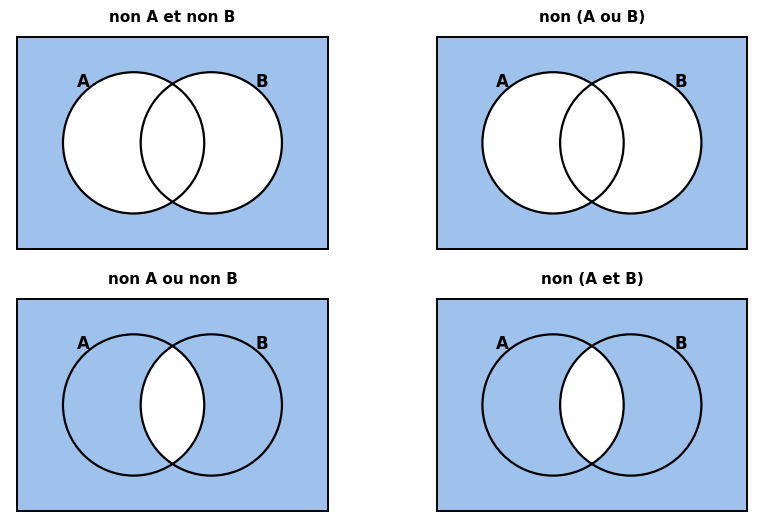

In [26]:
def venn_regions(in_a, in_b):
    """[not A and not B, not (A or B), not A or not B, not (A and B)]: four boolean arrays, point by point."""
    return [~in_a & ~in_b, ~(in_a | in_b), ~in_a | ~in_b, ~(in_a & in_b)]


show_regions(xs, ys, venn_regions(in_a, in_b), TITLES)

**Vérifications automatiques** (la figure elle-même se juge à l'œil).

In [27]:
with checked("R4.23 vérifications"):
    regions = [np.asarray(mask, dtype=bool) for mask in venn_regions(in_a, in_b)]
    outside, only_a, both = (0, 140), (100, 60), (100, 150)      # three points of the grid (row, column)
    problems = []
    if len(regions) != 4 or any(mask.shape != in_a.shape for mask in regions):
        problems.append("quatre tableaux de booléens de la forme de in_a")
    else:
        if not regions[0][outside] or regions[0][only_a]:
            problems.append("le 1ᵉʳ : les points qui ne sont ni dans A ni dans B")
        if not regions[2][only_a] or regions[2][both]:
            problems.append("le 3ᵉ : les points qui manquent à A ou à B")
        if not np.array_equal(regions[0], regions[1]) or not np.array_equal(regions[2], regions[3]):
            problems.append("le 2ᵉ égal au 1ᵉʳ, et le 4ᵉ égal au 3ᵉ, point par point")
    if problems:
        print("❌ Ex R4.23 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R4.23 : les deux paires de régions coïncident point par point ; écris dans ta copie la loi "
              "qu'elles illustrent.")

✅ Ex R4.23 : les deux paires de régions coïncident point par point ; écris dans ta copie la loi qu'elles illustrent.


💡 Les régions 1 et 2 coïncident, et 3 et 4 aussi : ce sont les lois de De Morgan, $\overline{A \cup B} = \bar{A} \cap \bar{B}$ et $\overline{A \cap B} = \bar{A} \cup \bar{B}$. La figure ne démontre rien pour tous les ensembles ; la table de vérité de R4.1 le fait, parce qu'un point est dans $A$ ou non, et dans $B$ ou non : quatre cas, tous vérifiés.

## Partie C · Σ, Π et récurrence

Fiche §5, §7 et §8. Σ et Π dans `mymath/logic.py`, une formule vérifiée mille fois puis démontrée, deux récurrences fausses, et une démonstration mise au propre.

### Ex R4.18 — Σ et Π en Python · `sum_over`, `prod_over` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer Σ et Π avec leurs bornes incluses, et les cas de la somme et du produit vides.  
**Prérequis :** fiche §5 · **mymath :** `logic.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en R2 et R3). Ouvre ta copie `mon_travail/mymath/logic.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Les tests comparent tes résultats à SymPy et à une évaluation directe.

Écris `sum_over(f, start, stop)` et `prod_over(f, start, stop)` : la somme et le produit des `f(k)` pour `k` allant de `start` à `stop`, **les deux bornes incluses**, comme $\sum_{k=\text{start}}^{\text{stop}} f(k)$ et $\prod_{k=\text{start}}^{\text{stop}} f(k)$. Une boucle `for` sur un `range` et un total suffisent ; réfléchis à la valeur de départ du total, et à ce que rendent les deux fonctions quand `stop < start` (fiche §5).

La vérification calcule $\sum_{k=1}^{5} k(k+1)$, une somme vide, $\prod_{k=1}^{10} 2$ et un produit vide, puis $\sum_{k=1}^{10} \frac{1}{2^k}$.

In [28]:
mymath = wbm.load_mymath("ref")
print("a)", [mymath.logic.sum_over(lambda k: k * (k + 1), 1, 5), mymath.logic.sum_over(lambda k: k, 5, 4),
             mymath.logic.prod_over(lambda k: 2, 1, 10), mymath.logic.prod_over(lambda k: k, 3, 2)])
print("b)", mymath.logic.sum_over(lambda k: 1 / 2**k, 1, 10))

a) [70, 0, 1024, 1]
b) 0.9990234375


In [29]:
wbm.record("R4.18a", [70, 0, 1024, 1],
           mistakes={"stop est inclus : range(start, stop + 1)": [40, 0, 512, 1],
                     "un produit part de 1, pas de 0": [70, 0, 0, 0],
                     "un produit vide vaut 1, l'élément neutre de la multiplication": [70, 0, 1024, 0]})
wbm.record("R4.18b", 0.9990234375, decimals=6,
           mistakes={"stop est inclus : range(start, stop + 1)": 0.998046875})

WBM_ANSWER {"decimals": 0, "element_hashes": ["77cfe8a18bd1111117e7966957f7cd27acbe9c5c655a332b49b6a0aca2d6b8f9", "11d48add632570ed5f42dfeb54e5c4ab473af9dfe8659f3b35d91f81b09b0202", "25376774389f3419298bb7516a386dab1b9f22936fa09dda54fd58835b76adc6", "79de8ba48ce84833e107cab6c85f07271d471b18095a397c5995dd48f513a1e3"], "hash": "3e9d804a7d770f03a94bc46cc8e538ee5f805df24e415a68e2218dd0031078a3", "id": "R4.18a", "integer": true, "kind": "array", "mistakes": {"331b117c1532d63c6864c22f7e80b2fe7466d9f72a4b80346c5bd2fc0b02280e": "un produit vide vaut 1, l'élément neutre de la multiplication", "573fd9b1c726b02263ef2a7c4991a0d1d8254b40b8c85df4846d5b192da321a0": "stop est inclus : range(start, stop + 1)", "7748340c2b7a4285190367aa852cae6aa4228eaa94947dbc22e1a58fef92745d": "un produit part de 1, pas de 0"}, "shape": [4]}
📝 Ex R4.18a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"decimals": 6, "hash": "d11702652ec5f0e7217ce105720d7176a1e10aa453d6744f4151675757195b88", "hash_coarse": "af4

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [30]:
run_pytest_group("tests/test_r4_logic.py", "test_sum_over_ or test_prod_over_", impl="ref")

pytest: 15 passed, 30 deselected in 0.44s


💡 La somme part de 0 et le produit de 1 : ce sont les éléments neutres, et c'est aussi ce que valent une somme et un produit vides. Et $\sum_{k=1}^{n} \frac{1}{2^k} = 1 - \frac{1}{2^n}$ (tu le démontreras en R5) : ici $1 - \frac{1}{1\,024}$.

### Ex R4.22 — Vérifier une formule de somme de 1 à 1 000, puis la démontrer 🔬 ★★ ⏱️ 20 min
**Objectif :** vérifier une formule sur mille cas, voir une formule fausse qui colle aux premiers cas, puis démontrer la vraie.  
**Prérequis :** fiche §5 et §7 ; R4.12 · **Parcours :** C

On conjecture la **formule A** : pour tout entier $n \ge 1$, $\displaystyle\sum_{k=1}^{n} k^3 = \left(\frac{n(n+1)}{2}\right)^2$. Un camarade propose la **formule B** : $\displaystyle\sum_{k=1}^{n} k^3 = \frac{n^2(n+1)^2}{4} + (n - 1)(n - 2)(n - 3)$.

Complète les trois fonctions (avec `//` pour les divisions, qui tombent juste : les résultats restent des entiers exacts). La vérification calcule :
- a) $\sum_{k=1}^{1000} k^3$ ;
- b) le nombre d'entiers $n$ de 1 à 1 000 pour lesquels la formule A **diffère** de la somme ;
- c) le plus petit $n \ge 1$ pour lequel la formule B diffère de la somme.

Puis l'expérience trace les deux courbes. Dans ta copie : démontre la formule A par récurrence (comme R4.12 : isole le dernier terme, puis factorise par $(n + 1)^2$), et explique pourquoi la formule B est juste pour $n = 1, 2, 3$.

In [31]:
def sum_of_cubes(n):
    """1³ + 2³ + … + n³, added term by term (a loop, or sum over a range)."""
    return sum(k**3 for k in range(1, n + 1))


def formula_a(n):
    """(n(n + 1)/2)², computed with // so that it stays an exact integer."""
    return (n * (n + 1) // 2) ** 2


def formula_b(n):
    """The classmate's formula: n²(n + 1)²/4 + (n − 1)(n − 2)(n − 3), with //."""
    return n**2 * (n + 1) ** 2 // 4 + (n - 1) * (n - 2) * (n - 3)


print("a)", sum_of_cubes(1000))
print("b)", sum(sum_of_cubes(n) != formula_a(n) for n in range(1, 1001)))
print("c)", next(n for n in range(1, 1001) if sum_of_cubes(n) != formula_b(n)))

a) 250500250000
b) 0
c) 4


In [32]:
wbm.record("R4.22a", 250500250000,
           mistakes={"n est inclus : range(1, n + 1)": 249500250000})
wbm.record("R4.22b", 0,
           mistakes={"attention aux priorités : (n * (n + 1) // 2) ** 2, avec des parenthèses autour du produit": 1000})
wbm.record("R4.22c", 4,
           mistakes={"pour n = 1, 2 et 3, le produit (n − 1)(n − 2)(n − 3) est nul : la formule B y est juste": 1})

WBM_ANSWER {"hash": "119549711cb02871364a5e5e476b2501a2b36da4622a170ca278904d6c796f3d", "id": "R4.22a", "kind": "int", "magnitude": 11, "mistakes": {"0b45851259a6e0774ba3a4103ba0b67e1bad3e1abf440e8a0dbdef6c2713b048": "n est inclus : range(1, n + 1)"}, "sign": 1}
📝 Ex R4.22a : réponse enregistrée (int).
WBM_ANSWER {"hash": "b30c850a257eb4e522ad80647d22d3a54c3359270705bde0544885afb0940fef", "id": "R4.22b", "kind": "int", "magnitude": null, "mistakes": {"90b45f0e7bd23177149ee72f542d1661d5792e92ac16f1fd841a1fa2562d7ea5": "attention aux priorités : (n * (n + 1) // 2) ** 2, avec des parenthèses autour du produit"}, "sign": 0}
📝 Ex R4.22b : réponse enregistrée (int).
WBM_ANSWER {"hash": "442980dd81301a5d5a9e77d4a0016161c3bff7332defa23f924ae3f01a32d1ef", "id": "R4.22c", "kind": "int", "magnitude": 0, "mistakes": {"49b1c3017987a8584654e403c28a057ae4bb697c814f6262b01ea3c47cea3f40": "pour n = 1, 2 et 3, le produit (n − 1)(n − 2)(n − 3) est nul : la formule B y est juste"}, "sign": 1}
📝 Ex R4.22c 

**L'expérience** : la somme et la formule B pour $n = 1$ à 12.

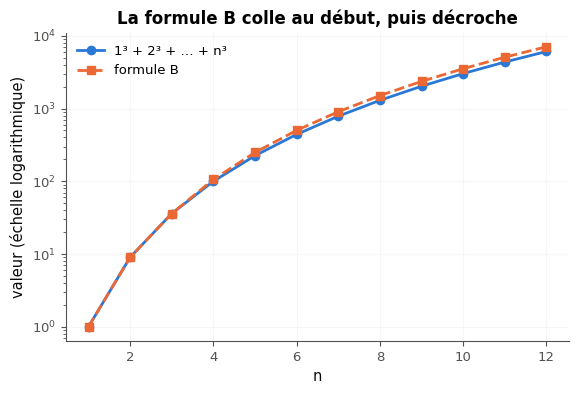

In [33]:
with checked("R4.22 figure"):
    ns = list(range(1, 13))
    cubes, proposed = [sum_of_cubes(n) for n in ns], [formula_b(n) for n in ns]   # before the figure
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(ns, cubes, "o-", label="1³ + 2³ + … + n³")
    ax.plot(ns, proposed, "s--", label="formule B")
    ax.set_yscale("log")
    ax.set_xlabel("n")
    ax.set_ylabel("valeur (échelle logarithmique)")
    ax.set_title("La formule B colle au début, puis décroche")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()

💡 La formule A est vraie pour tout $n$ (la récurrence le démontre) ; mille vérifications ne le démontraient pas, mais rendaient la conjecture crédible. La formule B montre le danger inverse : elle colle à la somme pour $n = 1, 2, 3$, car son terme en trop $(n - 1)(n - 2)(n - 3)$ s'annule en ces trois valeurs, puis s'en écarte.

### Ex R4.24 — Chasse à l'erreur : une « démonstration » par récurrence qui prouve le faux 🐛 ★★ ⏱️ 20 min
**Objectif :** repérer ce qui manque ou ce qui ne marche pas dans une récurrence.  
**Prérequis :** fiche §7 et §8 ; R4.12 · **Parcours :** C, E

Deux « démonstrations » par récurrence prouvent des choses fausses. **Sans rien exécuter d'abord**, trouve ce qui ne va pas.

**Preuve 1.** « Pour tout entier $n \ge 0$, $5^n + 1$ est divisible par 4. *Hérédité* : soit $n \ge 0$ tel que $5^n + 1 = 4m$, avec $m$ entier. Alors $5^{n+1} + 1 = 5 \times 5^n + 1 = 5(5^n + 1) - 4 = 20m - 4 = 4(5m - 1)$, divisible par 4. Donc, par récurrence, la propriété est vraie pour tout $n \ge 0$. »

**Preuve 2.** « Dans tout groupe de $n \ge 1$ boules, toutes les boules ont la même couleur. »

| | Ligne |
|---|---|
| A | Pour $n \ge 1$, notons $P(n)$ : « dans tout groupe de $n$ boules, toutes ont la même couleur ». |
| B | Initialisation : un groupe d'une seule boule n'a qu'une couleur, donc $P(1)$ est vraie. |
| C | Hérédité : soit $n \ge 1$ tel que $P(n)$ est vraie, et un groupe de $n + 1$ boules numérotées de 1 à $n + 1$. |
| D | Les boules 1 à $n$ forment un groupe de $n$ boules : d'après $P(n)$, elles ont toutes la même couleur. |
| E | Les boules 2 à $n + 1$ forment aussi un groupe de $n$ boules : elles ont toutes la même couleur. |
| F | La boule 2 appartient aux deux groupes, donc les deux groupes ont la même couleur, et les $n + 1$ boules aussi. |
| G | Par récurrence, $P(n)$ est vraie pour tout $n \ge 1$. |

- a) Preuve 1 : quelle étape manque ? 1 pour l'initialisation, 2 pour l'hérédité.
- b) Preuve 1 : combien d'entiers $n$ de 0 à 20 rendent $5^n + 1$ divisible par 4 ?
- c) Preuve 2 : la lettre de la ligne fausse (un texte).
- d) Preuve 2 : la plus petite valeur de $n$ pour laquelle le texte ne démontre pas « $P(n) \Rightarrow P(n + 1)$ ».
- e) Preuve 2 : $P(2)$ est-elle vraie ?

Puis, dans ta copie : pourquoi la preuve 1 ne peut-elle pas être réparée, alors que son hérédité est juste ? Et que montre la preuve 2 sur l'hérédité ?

In [34]:
print("Preuve 1, 5**n + 1 pour n = 0 à 5 :", [5**n + 1 for n in range(6)])
print("divisibles par 4 de 0 à 20 :", sum((5**n + 1) % 4 == 0 for n in range(21)))
print("Preuve 2, n = 1 : les boules 1 à 1 et 2 à 2 forment les groupes", [1], "et", [2], "-> aucune boule commune")

Preuve 1, 5**n + 1 pour n = 0 à 5 : [2, 6, 26, 126, 626, 3126]
divisibles par 4 de 0 à 20 : 0
Preuve 2, n = 1 : les boules 1 à 1 et 2 à 2 forment les groupes [1] et [2] -> aucune boule commune


In [35]:
wbm.record("R4.24a", 1, choices=[1, 2],
           mistakes={"l'hérédité est écrite, et son calcul est juste : refais-le": 2})
wbm.record("R4.24b", 0,
           mistakes={"teste n = 0 : 5⁰ + 1 = 2 ; puis regarde le reste de 5ⁿ dans la division par 4": 21})
wbm.record("R4.24c", "F",
           mistakes={"cette ligne est juste : cherche celle qui ne vaut pas pour toutes les valeurs de n":
                         {"A", "B", "C", "D", "E", "G"}})
wbm.record("R4.24d", 1,
           mistakes={"pour n = 2, les boules 1 à 2 et 2 à 3 partagent bien la boule 2 : essaie une valeur plus "
                     "petite": 2,
                     "l'hérédité part de n ≥ 1": 0})
wbm.record("R4.24e", False, mistakes={"deux boules peuvent avoir deux couleurs différentes": True})

WBM_ANSWER {"choices": ["1", "2"], "hash": "e7cc2321b6ecdfd5bda784bddcfcd65670612a55e83374a7d95ab508d709ac79", "id": "R4.24a", "kind": "int", "magnitude": 0, "mistakes": {"dbcda7d58932d0b499508e04ef18fa819004046c35811594a303e3ef4f7e7c93": "l'hérédité est écrite, et son calcul est juste : refais-le"}, "sign": 1}
📝 Ex R4.24a : réponse enregistrée (int).
WBM_ANSWER {"hash": "8fc3709dca3af1fb6b943ba3a696b3a662c9230d97b9b4efc4d6282ae7759cc6", "id": "R4.24b", "kind": "int", "magnitude": null, "mistakes": {"5d30fd338304a42534b67c9bd929e13874f7a18336ed8d034b954fe0ab22db37": "teste n = 0 : 5⁰ + 1 = 2 ; puis regarde le reste de 5ⁿ dans la division par 4"}, "sign": 0}
📝 Ex R4.24b : réponse enregistrée (int).
WBM_ANSWER {"hash": "7c5a40cb8ca255f6fe9f8005380e5b7d47864499e9f8acc222dcbe8c3ef24131", "id": "R4.24c", "kind": "str", "mistakes": {"6d1fcb3e8d8a8f43ccab8f5352ae9d46425e4c40155ddd2036b4876700746087": "cette ligne est juste : cherche celle qui ne vaut pas pour toutes les valeurs de n", "7f2623

💡 Preuve 1 : $5 \equiv 1$ modulo 4, donc $5^n + 1$ laisse toujours le reste 2 ; aucun domino ne tombe. Preuve 2 : pour passer de 1 à 2 boules, les groupes « boules 1 à 1 » et « boules 2 à 2 » n'ont aucune boule commune, et la ligne F est fausse ; un seul domino qui ne fait pas tomber le suivant suffit à tout arrêter.

### Ex R4.25 — Rédiger une démonstration propre en LaTeX 🛠️ ★ ⏱️ 20 min
**Objectif :** mettre au propre une démonstration, avec ses formules en LaTeX, comme dans un rapport ou un notebook partagé.  
**Prérequis :** fiche §8 ; R4.12 ; R0 (LaTeX) · **Parcours :** C

Recopie **au propre**, dans la cellule Markdown ci-dessous, ta démonstration par récurrence de R4.12 ($\sum_{k=1}^{n} k = \frac{n(n+1)}{2}$), en LaTeX. Elle doit contenir :
- l'énoncé de la propriété, avec son quantificateur, et la définition de $P(n)$ ;
- trois paragraphes titrés *Initialisation*, *Hérédité*, *Conclusion* ;
- dans l'hérédité, un calcul centré entre `$$`, qui fait apparaître la somme jusqu'à $n$ et l'endroit où l'hypothèse de récurrence sert ;
- un signe de fin, `$\blacksquare$`.

Commandes utiles : `\sum_{k=1}^{n} k`, `\frac{n(n+1)}{2}`, `\ge`, `\Rightarrow`, `\displaystyle`. Exécute la cellule pour voir le rendu, corrige ce qui s'affiche mal, puis compare avec le modèle de `05_solutions.ipynb`.

**Un modèle** (d'autres rédactions sont justes : compare la structure, pas les mots).

**Propriété.** Pour tout entier $n \ge 1$, $\displaystyle\sum_{k=1}^{n} k = \frac{n(n+1)}{2}$.

*Démonstration.* Pour tout entier $n \ge 1$, notons $P(n)$ la propriété « $\sum_{k=1}^{n} k = \frac{n(n+1)}{2}$ ».

*Initialisation.* Pour $n = 1$, la somme vaut $1$ et $\frac{1 \times 2}{2} = 1$ : $P(1)$ est vraie.

*Hérédité.* Soit $n \ge 1$ un entier tel que $P(n)$ est vraie. En isolant le dernier terme, puis en utilisant $P(n)$ :
$$\sum_{k=1}^{n+1} k = \sum_{k=1}^{n} k + (n + 1) = \frac{n(n+1)}{2} + (n + 1) = \frac{(n + 1)(n + 2)}{2}.$$
C'est $P(n + 1)$.

*Conclusion.* $P(1)$ est vraie et, pour tout $n \ge 1$, $P(n) \Rightarrow P(n + 1)$ : par récurrence, $P(n)$ est vraie pour tout entier $n \ge 1$. $\blacksquare$

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Dresses-tu une table de vérité, et nies-tu une phrase avec « et », « ou », « pour tout », « il existe » ?
2. Distingues-tu implication, réciproque et contraposée, et calcules-tu unions, intersections, cardinaux, sommes Σ et produits Π ?
3. Choisis-tu un raisonnement adapté, et sais-tu rédiger une récurrence complète ?

**La suite** : R5, *Suites*. Dans workbookIA, continue le chapitre 0A au rythme de ton tableau de bord.